# Cryptocurrency Market Analysis Using Exploratory Data Analysis (EDA)

## 1. Introduction

Cryptocurrency is a digital asset whose market price can fluctuate significantly over time. Cryptocurrencies such as Bitcoin, Ethereum, Solana, XRP, Dogecoin, BNB, and Cardano are traded globally, and their prices are influenced by market demand, investor sentiment, trading activity, and other factors.

This project uses Exploratory Data Analysis (EDA) to examine cryptocurrency market data collected from Yahoo Finance. Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn are used to clean, analyze, and visualize the data.

The analysis focuses on historical price movements, trading volume, percentage returns, volatility, and relationships between cryptocurrencies. Prices are also converted from US dollars (USD) to Indian rupees (INR) to make the results easier to interpret in an Indian context.

**Data source:** Yahoo Finance  
**Programming language:** Python  
**Analysis type:** Exploratory Data Analysis (EDA)


### Research Question

Do alternative cryptocurrencies become more closely correlated with Bitcoin during periods of high Bitcoin volatility?

This project investigates this question by comparing altcoin–Bitcoin daily return correlations during high- and lower-volatility periods, alongside broader analysis of historical performance and risk.


## 2. Problem Statement

Cryptocurrency markets experience frequent price fluctuations, making it challenging to compare the performance and risk of different digital assets. A systematic analysis of historical market data can help identify price trends, changes in trading activity, periods of high volatility, and relationships between cryptocurrencies.

This project aims to explore cryptocurrency market data using statistical analysis and data visualization to identify meaningful patterns and summarize historical market behaviour.

## 3. Objectives

The main objectives of this project are:

1. To collect cryptocurrency market data from Yahoo Finance.
2. To understand the structure and characteristics of the dataset.
3. To clean the data and handle missing or duplicate records.
4. To convert cryptocurrency prices from USD to INR.
5. To analyze opening, closing, highest, and lowest prices.
6. To examine percentage returns and price volatility.
7. To compare cryptocurrency performance over the selected period.
8. To study trading volume and correlations between cryptocurrencies.
9. To create meaningful visualizations using Matplotlib and Seaborn.
10. To derive evidence-based insights from the analysis.

## 4. Tools and Technologies

The following tools and libraries are used in this project:

- **Python:** Main programming language.
- **Yahoo Finance / yfinance:** Source for historical cryptocurrency market data.
- **Pandas:** Data manipulation and analysis.
- **NumPy:** Numerical calculations.
- **Matplotlib:** Data visualization.
- **Seaborn:** Statistical charts and correlation heatmaps.
- **Requests:** Retrieval of exchange-rate data.
- **Jupyter Notebook:** Interactive environment for documenting and executing the analysis.

### Data source limitations

The `yfinance` library is an unofficial interface to Yahoo Finance. Data availability and supported intervals can change, and access is not guaranteed. The project therefore uses the latest available historical observations rather than assuming every fetched price is a real-time quote.

## 5. Importing Libraries

The required Python libraries are imported to support data collection, cleaning, numerical analysis, and visualization. Seaborn's plotting theme is configured to improve chart readability.

In [159]:
import pandas as pd
import numpy as np
import yfinance as yf
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings(
    "ignore",
    category=FutureWarning,
    module=r"yfinance\..*"
)
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!



## 6. Data Collection

Historical cryptocurrency market data is collected from Yahoo Finance using the `yfinance` Python library.

This project analyses seven cryptocurrencies:

- Bitcoin (BTC-USD)
- Ethereum (ETH-USD)
- Solana (SOL-USD)
- XRP (XRP-USD)
- Dogecoin (DOGE-USD)
- BNB (BNB-USD)
- Cardano (ADA-USD)

The dataset covers approximately one year of daily historical data. It includes opening price, highest price, lowest price, closing price, adjusted closing price when available, and trading volume.

Daily data is used to study historical performance, daily returns, volatility, maximum drawdown, and relationships between cryptocurrency returns.

**Data source:** Yahoo Finance, accessed through the `yfinance` Python library.

**Limitation:** This project uses historical daily data and does not guarantee a continuously updated real-time price feed.


In [160]:



# List of cryptocurrencies to analyse
symbols = [
    "BTC-USD",
    "ETH-USD",
    "SOL-USD",
    "XRP-USD",
    "DOGE-USD",
    "BNB-USD",
    "ADA-USD"
]

# Store downloaded data
frames = []
errors = []

# Download one year of daily historical data
for symbol in symbols:
    try:
        df = yf.Ticker(symbol).history(
            period="1y",
            interval="1d",
            auto_adjust=False,
            timeout=20
        )

        if df.empty:
            errors.append(f"No data available for {symbol}")
            continue

        # Convert the index into a regular column
        df = df.reset_index()

        # Standardise the date column name
        if "Datetime" not in df.columns and "Date" in df.columns:
            df = df.rename(columns={"Date": "Datetime"})

        if "Datetime" not in df.columns:
            errors.append(
                f"Date column missing for {symbol}: "
                f"{df.columns.tolist()}"
            )
            continue

        # Identify the cryptocurrency
        df["Symbol"] = symbol

        frames.append(df)

        print(f"Downloaded successfully: {symbol}")

    except Exception as e:
        errors.append(f"{symbol}: {e}")

# Combine all downloaded data
if not frames:
    raise RuntimeError(
        "No data was downloaded. Check your internet connection "
        "and try running this cell again."
    )

crypto = pd.concat(frames, ignore_index=True)

# Standardise date format
crypto["Datetime"] = pd.to_datetime(
    crypto["Datetime"],
    utc=True,
    errors="coerce"
)

# Clean essential fields and remove duplicate observations
crypto = crypto.dropna(
    subset=["Datetime", "Close", "Symbol"]
)

crypto = crypto.drop_duplicates(
    subset=["Datetime", "Symbol"]
)

# Sort data by cryptocurrency and date
crypto = crypto.sort_values(
    ["Symbol", "Datetime"]
).reset_index(drop=True)

# Display collection results
print("\nDATA COLLECTION SUMMARY")
print("-" * 40)
print("Dataset shape:", crypto.shape)
print("Total observations:", len(crypto))
print("Cryptocurrencies collected:", crypto["Symbol"].nunique())
print("First date:", crypto["Datetime"].min())
print("Last date:", crypto["Datetime"].max())

print("\nRecords per cryptocurrency:")
display(
    crypto.groupby("Symbol")
    .size()
    .rename("Record_Count")
    .to_frame()
)

print("\nFirst five rows:")
display(crypto.head())

# Display any collection errors
if errors:
    print("\nWarnings during data collection:")
    for error in errors:
        print("-", error)
else:
    print("\nAll requested cryptocurrencies were downloaded successfully.")



Downloaded successfully: BTC-USD
Downloaded successfully: ETH-USD
Downloaded successfully: SOL-USD
Downloaded successfully: XRP-USD
Downloaded successfully: DOGE-USD
Downloaded successfully: BNB-USD
Downloaded successfully: ADA-USD

DATA COLLECTION SUMMARY
----------------------------------------
Dataset shape: (2562, 10)
Total observations: 2562
Cryptocurrencies collected: 7
First date: 2025-10-21 00:00:00+00:00
Last date: 2026-10-21 00:00:00+00:00

Records per cryptocurrency:


,Record_Count
Symbol,
ADA-USD,366
BNB-USD,366
BTC-USD,366
DOGE-USD,366
ETH-USD,366
SOL-USD,366
XRP-USD,366



First five rows:


,Datetime,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Symbol
0,2025-10-21 00:00:00+00:00,0.663214,0.684629,0.637932,0.642914,0.642914,1195836837,0.0,0.0,ADA-USD
1,2025-10-22 00:00:00+00:00,0.642921,0.646684,0.611353,0.623972,0.623972,1083621498,0.0,0.0,ADA-USD
2,2025-10-23 00:00:00+00:00,0.623972,0.652958,0.623254,0.642845,0.642845,786265376,0.0,0.0,ADA-USD
3,2025-10-24 00:00:00+00:00,0.642849,0.658830,0.639687,0.655891,0.655891,838536144,0.0,0.0,ADA-USD
4,2025-10-25 00:00:00+00:00,0.655894,0.658647,0.649007,0.654663,0.654663,469372495,0.0,0.0,ADA-USD



All requested cryptocurrencies were downloaded successfully.



## 7. Understanding the Dataset

After collecting cryptocurrency market data from Yahoo Finance, the next step is to understand the structure and characteristics of the dataset.

This section examines:

- Dataset dimensions (number of rows and columns).
- Column names and data types.
- Descriptive statistics for numerical variables.
- Number of observations available for each cryptocurrency.
- First and last available dates for each cryptocurrency.
- Sample records to understand how the data is organised.

This exploration helps verify successful data collection and identify any differences in data availability before performing data cleaning and further analysis.


In [161]:

# 1. Check dataset dimensions
print("=" * 50)
print("DATASET DIMENSIONS")
print("=" * 50)

print("Number of rows:", crypto.shape[0])
print("Number of columns:", crypto.shape[1])


# 2. Display column names
print("\nCOLUMN NAMES")
print(crypto.columns.tolist())


# 3. Check data types and non-null values
print("\nDATASET INFORMATION")
crypto.info()


# 4. Display first five records
print("\nFIRST FIVE RECORDS")
display(crypto.head())


# 5. Descriptive statistics
print("\nDESCRIPTIVE STATISTICS")
display(crypto.describe())


# 6. List available cryptocurrencies
print("\nCRYPTOCURRENCIES COLLECTED")
print(sorted(crypto["Symbol"].unique()))


# 7. Count records for each cryptocurrency
print("\nRECORD COUNT BY CRYPTOCURRENCY")

record_counts = (
    crypto.groupby("Symbol")
    .size()
    .reset_index(name="Record_Count")
)

display(record_counts)


# 8. Check date coverage for each cryptocurrency
print("\nDATE COVERAGE")

date_summary = (
    crypto.groupby("Symbol")
    .agg(
        First_Date=("Datetime", "min"),
        Last_Date=("Datetime", "max"),
        Total_Records=("Datetime", "count")
    )
)

display(date_summary)


DATASET DIMENSIONS
Number of rows: 2562
Number of columns: 10

COLUMN NAMES
['Datetime', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits', 'Symbol']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2562 entries, 0 to 2561
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   Datetime      2562 non-null   datetime64[ns, UTC]
 1   Open          2562 non-null   float64            
 2   High          2562 non-null   float64            
 3   Low           2562 non-null   float64            
 4   Close         2562 non-null   float64            
 5   Adj Close     2562 non-null   float64            
 6   Volume        2562 non-null   int64              
 7   Dividends     2562 non-null   float64            
 8   Stock Splits  2562 non-null   float64            
 9   Symbol        2562 non-null   object             
dtypes: datetime64[ns, UTC](1

,Datetime,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Symbol
0,2025-10-21 00:00:00+00:00,0.663214,0.684629,0.637932,0.642914,0.642914,1195836837,0.0,0.0,ADA-USD
1,2025-10-22 00:00:00+00:00,0.642921,0.646684,0.611353,0.623972,0.623972,1083621498,0.0,0.0,ADA-USD
2,2025-10-23 00:00:00+00:00,0.623972,0.652958,0.623254,0.642845,0.642845,786265376,0.0,0.0,ADA-USD
3,2025-10-24 00:00:00+00:00,0.642849,0.658830,0.639687,0.655891,0.655891,838536144,0.0,0.0,ADA-USD
4,2025-10-25 00:00:00+00:00,0.655894,0.658647,0.649007,0.654663,0.654663,469372495,0.0,0.0,ADA-USD



DESCRIPTIVE STATISTICS


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
count,2562.000000,2562.000000,2562.000000,2562.000000,2562.000000,2.562000e+03,2562.0,2562.0
mean,11625.199368,11812.548839,11423.144710,11614.426749,11614.426749,9.829795e+09,0.0,0.0
std,27577.732015,28011.783418,27106.034109,27546.618927,27546.618927,1.605101e+10,0.0,0.0
min,0.068987,0.070037,0.067973,0.068988,0.068988,1.200826e+08,0.0,0.0
25%,0.356262,0.362588,0.347887,0.353739,0.353739,1.084522e+09,0.0,0.0
50%,90.443424,92.834660,87.687286,90.444073,90.444073,2.414666e+09,0.0,0.0
75%,1968.127167,2020.214661,1920.654572,1968.277496,1968.277496,1.139485e+10,0.0,0.0
max,114479.851562,116273.312500,113882.289062,114472.445312,114472.445312,1.291575e+11,0.0,0.0



CRYPTOCURRENCIES COLLECTED
['ADA-USD', 'BNB-USD', 'BTC-USD', 'DOGE-USD', 'ETH-USD', 'SOL-USD', 'XRP-USD']

RECORD COUNT BY CRYPTOCURRENCY


,Symbol,Record_Count
0,ADA-USD,366
1,BNB-USD,366
2,BTC-USD,366
3,DOGE-USD,366
4,ETH-USD,366
5,SOL-USD,366
6,XRP-USD,366



DATE COVERAGE


,First_Date,Last_Date,Total_Records
Symbol,,,
ADA-USD,2025-10-21 00:00:00+00:00,2026-10-21 00:00:00+00:00,366
BNB-USD,2025-10-21 00:00:00+00:00,2026-10-21 00:00:00+00:00,366
BTC-USD,2025-10-21 00:00:00+00:00,2026-10-21 00:00:00+00:00,366
DOGE-USD,2025-10-21 00:00:00+00:00,2026-10-21 00:00:00+00:00,366
ETH-USD,2025-10-21 00:00:00+00:00,2026-10-21 00:00:00+00:00,366
SOL-USD,2025-10-21 00:00:00+00:00,2026-10-21 00:00:00+00:00,366
XRP-USD,2025-10-21 00:00:00+00:00,2026-10-21 00:00:00+00:00,366



## 8. Data Cleaning and Quality Checks

Data cleaning is an important step in preparing the cryptocurrency dataset for reliable analysis.

In this section, we will:

- Check missing values in each column.
- Identify and remove duplicate observations.
- Convert price and volume columns to numeric data types.
- Remove records with missing dates, cryptocurrency symbols, or essential prices.
- Check for zero or negative prices.
- Verify that the cleaned dataset contains valid observations.

Missing values in trading volume are not automatically replaced with zero because missing data does not necessarily mean that no trading occurred.


In [162]:

# Make a copy of the collected dataset
crypto = crypto.copy()

print("=" * 50)
print("DATA CLEANING AND QUALITY CHECKS")
print("=" * 50)

# 1. Check the original dataset size
print("\nDataset shape before cleaning:", crypto.shape)

# 2. Check missing values before cleaning
print("\nMissing values before cleaning:")
display(crypto.isna().sum().to_frame("Missing_Count"))

# 3. Convert numeric columns to numeric data types
numeric_cols = [
    "Open",
    "High",
    "Low",
    "Close",
    "Adj Close",
    "Volume"
]

for col in numeric_cols:
    if col in crypto.columns:
        crypto[col] = pd.to_numeric(
            crypto[col],
            errors="coerce"
        )

# 4. Remove duplicate date-symbol observations
duplicates_before = crypto.duplicated(
    subset=["Datetime", "Symbol"]
).sum()

print("\nDuplicate observations found:", duplicates_before)

crypto = crypto.drop_duplicates(
    subset=["Datetime", "Symbol"]
).copy()

# 5. Remove rows missing essential fields
rows_before = len(crypto)

crypto = crypto.dropna(
    subset=["Datetime", "Symbol", "Open", "High", "Low", "Close"]
).copy()

print("Rows removed due to missing essential values:",
      rows_before - len(crypto))

# 6. Remove rows with zero or negative prices
rows_before = len(crypto)

price_cols = ["Open", "High", "Low", "Close"]

valid_prices = (crypto[price_cols] > 0).all(axis=1)

crypto = crypto[valid_prices].copy()

print("Rows removed due to invalid prices:",
      rows_before - len(crypto))

# 7. Check whether high and low prices are logically consistent
invalid_high_low = (
    (crypto["High"] < crypto["Low"])
    | (crypto["High"] < crypto["Open"])
    | (crypto["High"] < crypto["Close"])
    | (crypto["Low"] > crypto["Open"])
    | (crypto["Low"] > crypto["Close"])
)

print("Rows with inconsistent OHLC prices:",
      invalid_high_low.sum())

# 8. Sort the cleaned dataset
crypto = crypto.sort_values(
    ["Symbol", "Datetime"]
).reset_index(drop=True)

# 9. Final dataset size
print("\nDataset shape after cleaning:", crypto.shape)

# 10. Check missing values after cleaning
print("\nMissing values after cleaning:")
display(crypto.isna().sum().to_frame("Missing_Count"))

# 11. Confirm no duplicate date-symbol observations remain
print(
    "\nRemaining duplicate observations:",
    crypto.duplicated(["Datetime", "Symbol"]).sum()
)

# 12. Show the cleaned data
print("\nFirst five cleaned records:")
display(crypto.head())


DATA CLEANING AND QUALITY CHECKS

Dataset shape before cleaning: (2562, 10)

Missing values before cleaning:


,Missing_Count
Datetime,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0
Dividends,0
Stock Splits,0
Symbol,0



Duplicate observations found: 0
Rows removed due to missing essential values: 0
Rows removed due to invalid prices: 0
Rows with inconsistent OHLC prices: 3

Dataset shape after cleaning: (2562, 10)

Missing values after cleaning:


,Missing_Count
Datetime,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0
Dividends,0
Stock Splits,0
Symbol,0



Remaining duplicate observations: 0

First five cleaned records:


,Datetime,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Symbol
0,2025-10-21 00:00:00+00:00,0.663214,0.684629,0.637932,0.642914,0.642914,1195836837,0.0,0.0,ADA-USD
1,2025-10-22 00:00:00+00:00,0.642921,0.646684,0.611353,0.623972,0.623972,1083621498,0.0,0.0,ADA-USD
2,2025-10-23 00:00:00+00:00,0.623972,0.652958,0.623254,0.642845,0.642845,786265376,0.0,0.0,ADA-USD
3,2025-10-24 00:00:00+00:00,0.642849,0.658830,0.639687,0.655891,0.655891,838536144,0.0,0.0,ADA-USD
4,2025-10-25 00:00:00+00:00,0.655894,0.658647,0.649007,0.654663,0.654663,469372495,0.0,0.0,ADA-USD



## 9. Currency Conversion: USD to INR

Cryptocurrency prices collected from Yahoo Finance are quoted in US dollars (USD). To make the prices easier to understand for an Indian audience, this section converts them into Indian rupees (INR).

The USD/INR reference exchange rate is retrieved from the Frankfurter API.

**Formula:**

INR Price = USD Price × USD/INR Exchange Rate

**Important limitation:** A single reference exchange rate is applied to the entire historical dataset. Therefore, the converted prices are approximate INR equivalents and do not represent the actual historical INR price on each date.

The main return, volatility, and correlation analyses will use USD prices.


In [163]:

# Retrieve the USD/INR reference exchange rate
url = "https://api.frankfurter.dev/v2/rate/usd/inr"

try:
    response = requests.get(url, timeout=15)
    response.raise_for_status()

    fx_data = response.json()

    usd_inr = float(fx_data["rate"])
    fx_date = fx_data["date"]

    if not np.isfinite(usd_inr) or usd_inr <= 0:
        raise ValueError("Invalid USD/INR exchange rate.")

    # Convert USD prices to approximate INR values
    crypto["Close_INR_Approx"] = crypto["Close"] * usd_inr
    crypto["Open_INR_Approx"] = crypto["Open"] * usd_inr
    crypto["High_INR_Approx"] = crypto["High"] * usd_inr
    crypto["Low_INR_Approx"] = crypto["Low"] * usd_inr

    print("Currency conversion completed successfully.")
    print(f"USD/INR reference rate: {usd_inr:.4f}")
    print(f"Reference rate date: {fx_date}")
    print("Note: Historical INR prices are approximate.")

    display(
        crypto[
            [
                "Datetime",
                "Symbol",
                "Close",
                "Close_INR_Approx"
            ]
        ].head()
    )

except Exception as e:
    print("Could not retrieve the USD/INR exchange rate.")
    print("Details:", e)
    print("Check your internet connection or try again later.")


Currency conversion completed successfully.
USD/INR reference rate: 94.6600
Reference rate date: 2026-10-21
Note: Historical INR prices are approximate.


,Datetime,Symbol,Close,Close_INR_Approx
0,2025-10-21 00:00:00+00:00,ADA-USD,0.642914,60.858239
1,2025-10-22 00:00:00+00:00,ADA-USD,0.623972,59.065189
2,2025-10-23 00:00:00+00:00,ADA-USD,0.642845,60.851705
3,2025-10-24 00:00:00+00:00,ADA-USD,0.655891,62.086642
4,2025-10-25 00:00:00+00:00,ADA-USD,0.654663,61.970402



## 10. Feature Engineering

Feature engineering creates new variables that help analyse cryptocurrency market behaviour.

This section calculates:

- Daily Return (%): percentage change in closing price from the previous available observation.
- Daily Price Range (%): daily high-low range relative to the opening price.
- 7-Day Moving Average: average closing price over seven daily observations.
- 7-Day Rolling Volatility: standard deviation of daily returns over seven observations.
- Indexed Price: normalised price with the first observed closing price set to 100.
- Running Peak: highest closing price observed so far.
- Drawdown (%): percentage decline from the running peak.

These features help compare relative performance, price variability, and historical declines.


In [164]:

crypto = crypto.sort_values(["Symbol", "Datetime"]).copy()

# 1. Daily percentage returns
crypto["Daily_Return_Pct"] = (
    crypto.groupby("Symbol")["Close"]
    .pct_change(fill_method=None) * 100
)

# 2. Daily high-low range relative to opening price
crypto["Price_Range_Pct"] = (
    (crypto["High"] - crypto["Low"])
    / crypto["Open"].replace(0, np.nan)
) * 100

# 3. Seven-observation moving average
crypto["Moving_Average_7d"] = (
    crypto.groupby("Symbol")["Close"]
    .transform(lambda s: s.rolling(7, min_periods=7).mean())
)

# 4. Seven-observation rolling volatility
crypto["Rolling_Volatility_7d"] = (
    crypto.groupby("Symbol")["Daily_Return_Pct"]
    .transform(lambda s: s.rolling(7, min_periods=7).std())
)

# 5. Indexed price: first available price = 100
crypto["Indexed_Price"] = (
    crypto["Close"]
    / crypto.groupby("Symbol")["Close"].transform("first")
) * 100

# 6. Running peak
crypto["Running_Peak"] = (
    crypto.groupby("Symbol")["Close"].cummax()
)

# 7. Drawdown from running peak
crypto["Drawdown_Pct"] = (
    (crypto["Close"] / crypto["Running_Peak"]) - 1
) * 100

print("Feature engineering completed.")

display(
    crypto[
        [
            "Datetime", "Symbol", "Close",
            "Daily_Return_Pct", "Price_Range_Pct",
            "Moving_Average_7d", "Rolling_Volatility_7d",
            "Indexed_Price", "Drawdown_Pct"
        ]
    ].head(10)
)


Feature engineering completed.


,Datetime,Symbol,Close,Daily_Return_Pct,Price_Range_Pct,Moving_Average_7d,Rolling_Volatility_7d,Indexed_Price,Drawdown_Pct
0,2025-10-21 00:00:00+00:00,ADA-USD,0.642914,NaN,7.041018,NaN,NaN,100.000000,0.000000
1,2025-10-22 00:00:00+00:00,ADA-USD,0.623972,-2.946273,5.495389,NaN,NaN,97.053727,-2.946273
2,2025-10-23 00:00:00+00:00,ADA-USD,0.642845,3.024651,4.760466,NaN,NaN,99.989264,-0.010736
3,2025-10-24 00:00:00+00:00,ADA-USD,0.655891,2.029420,2.977835,NaN,NaN,102.018467,0.000000
4,2025-10-25 00:00:00+00:00,ADA-USD,0.654663,-0.187222,1.469746,NaN,NaN,101.827465,-0.187222
5,2025-10-26 00:00:00+00:00,ADA-USD,0.681063,4.032604,5.613415,NaN,NaN,105.933764,0.000000
6,2025-10-27 00:00:00+00:00,ADA-USD,0.667365,-2.011265,3.909055,0.652673,NaN,103.803155,-2.011265
7,2025-10-28 00:00:00+00:00,ADA-USD,0.646273,-3.160489,5.260406,0.653153,2.949327,100.522468,-5.108188
8,2025-10-29 00:00:00+00:00,ADA-USD,0.640165,-0.945118,3.461922,0.655466,2.689022,99.572412,-6.005028
9,2025-10-30 00:00:00+00:00,ADA-USD,0.601123,-6.098740,9.195489,0.649506,3.336504,93.499749,-11.737537



## 11. Univariate Analysis

Univariate analysis examines one variable at a time to understand its distribution, spread, and potential outliers.

This section examines closing prices and daily percentage returns for each cryptocurrency. Separate charts are used because the cryptocurrencies have different price levels.

Daily-return distributions are particularly useful for comparing the variability of percentage price changes across assets.


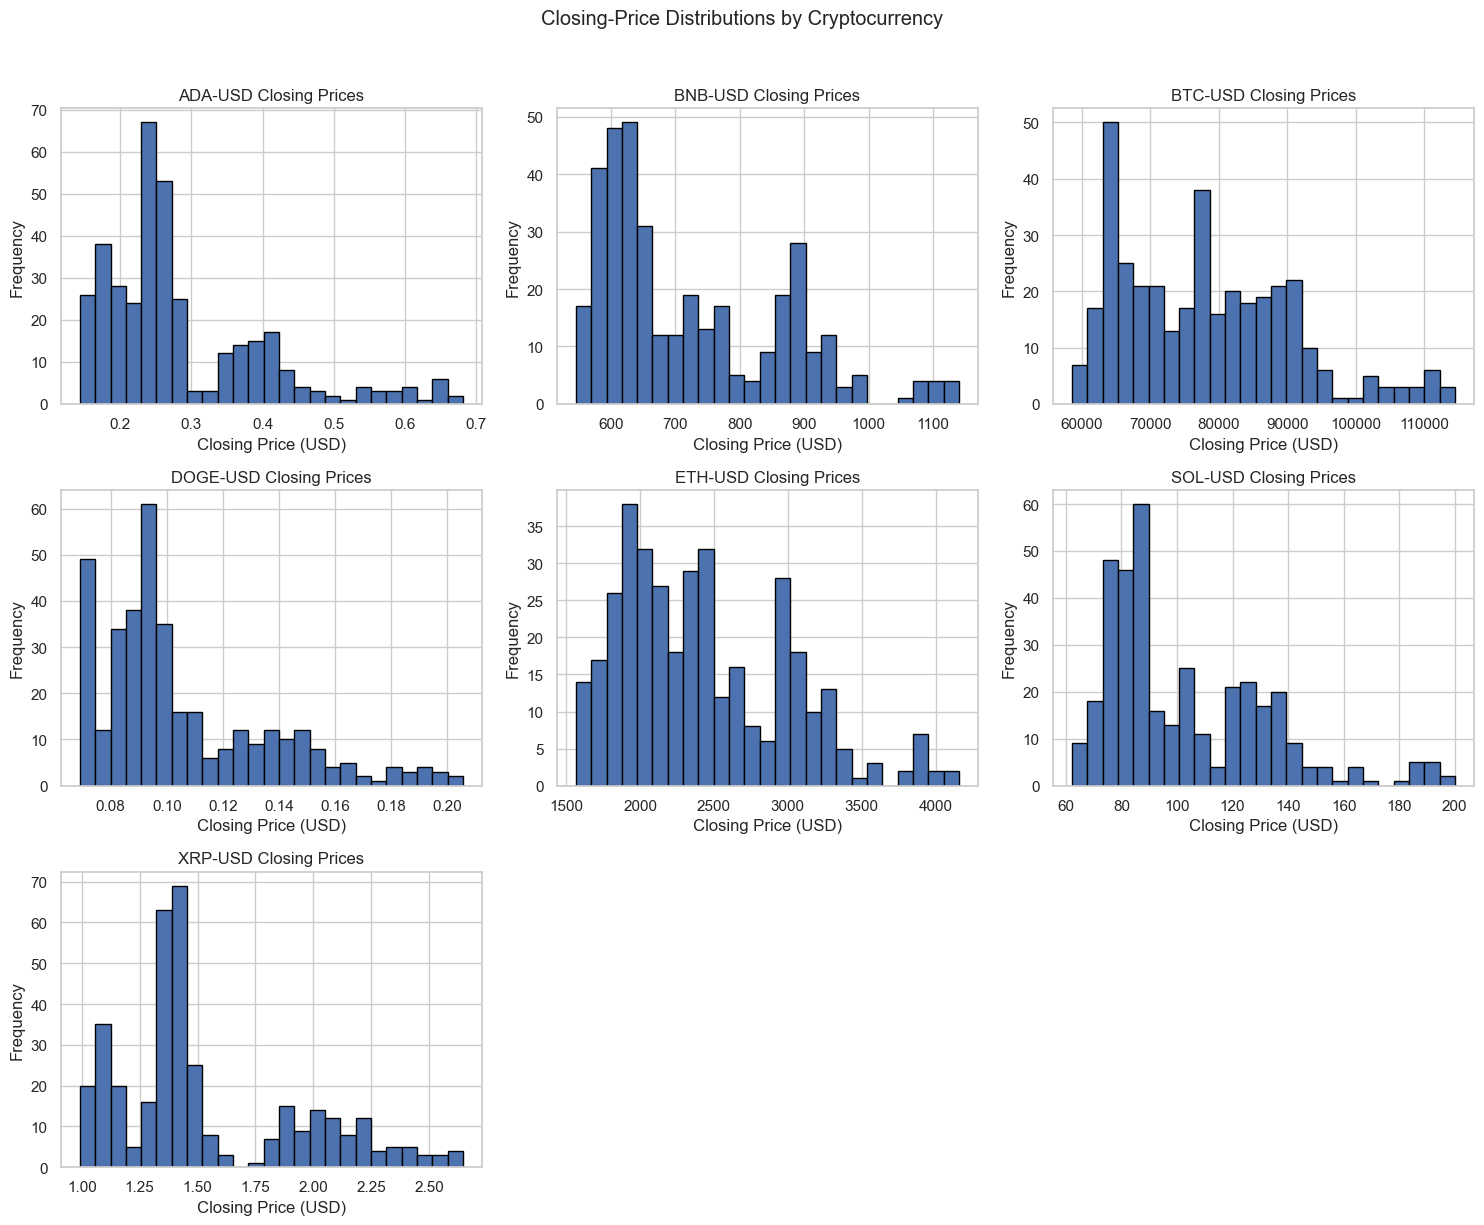

In [165]:

available_symbols = sorted(crypto["Symbol"].unique())

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, symbol in enumerate(available_symbols):
    prices = crypto.loc[
        crypto["Symbol"] == symbol, "Close"
    ].dropna()

    axes[i].hist(prices, bins=25, edgecolor="black")
    axes[i].set_title(f"{symbol} Closing Prices")
    axes[i].set_xlabel("Closing Price (USD)")
    axes[i].set_ylabel("Frequency")

for i in range(len(available_symbols), len(axes)):
    axes[i].set_visible(False)

plt.suptitle("Closing-Price Distributions by Cryptocurrency", y=1.02)
plt.tight_layout()
plt.show()


The histogram shows how frequently different closing-price values occur in the collected dataset. The distribution may be strongly affected by the difference in price levels between cryptocurrencies. This chart describes the pooled observations rather than the distribution of each cryptocurrency separately

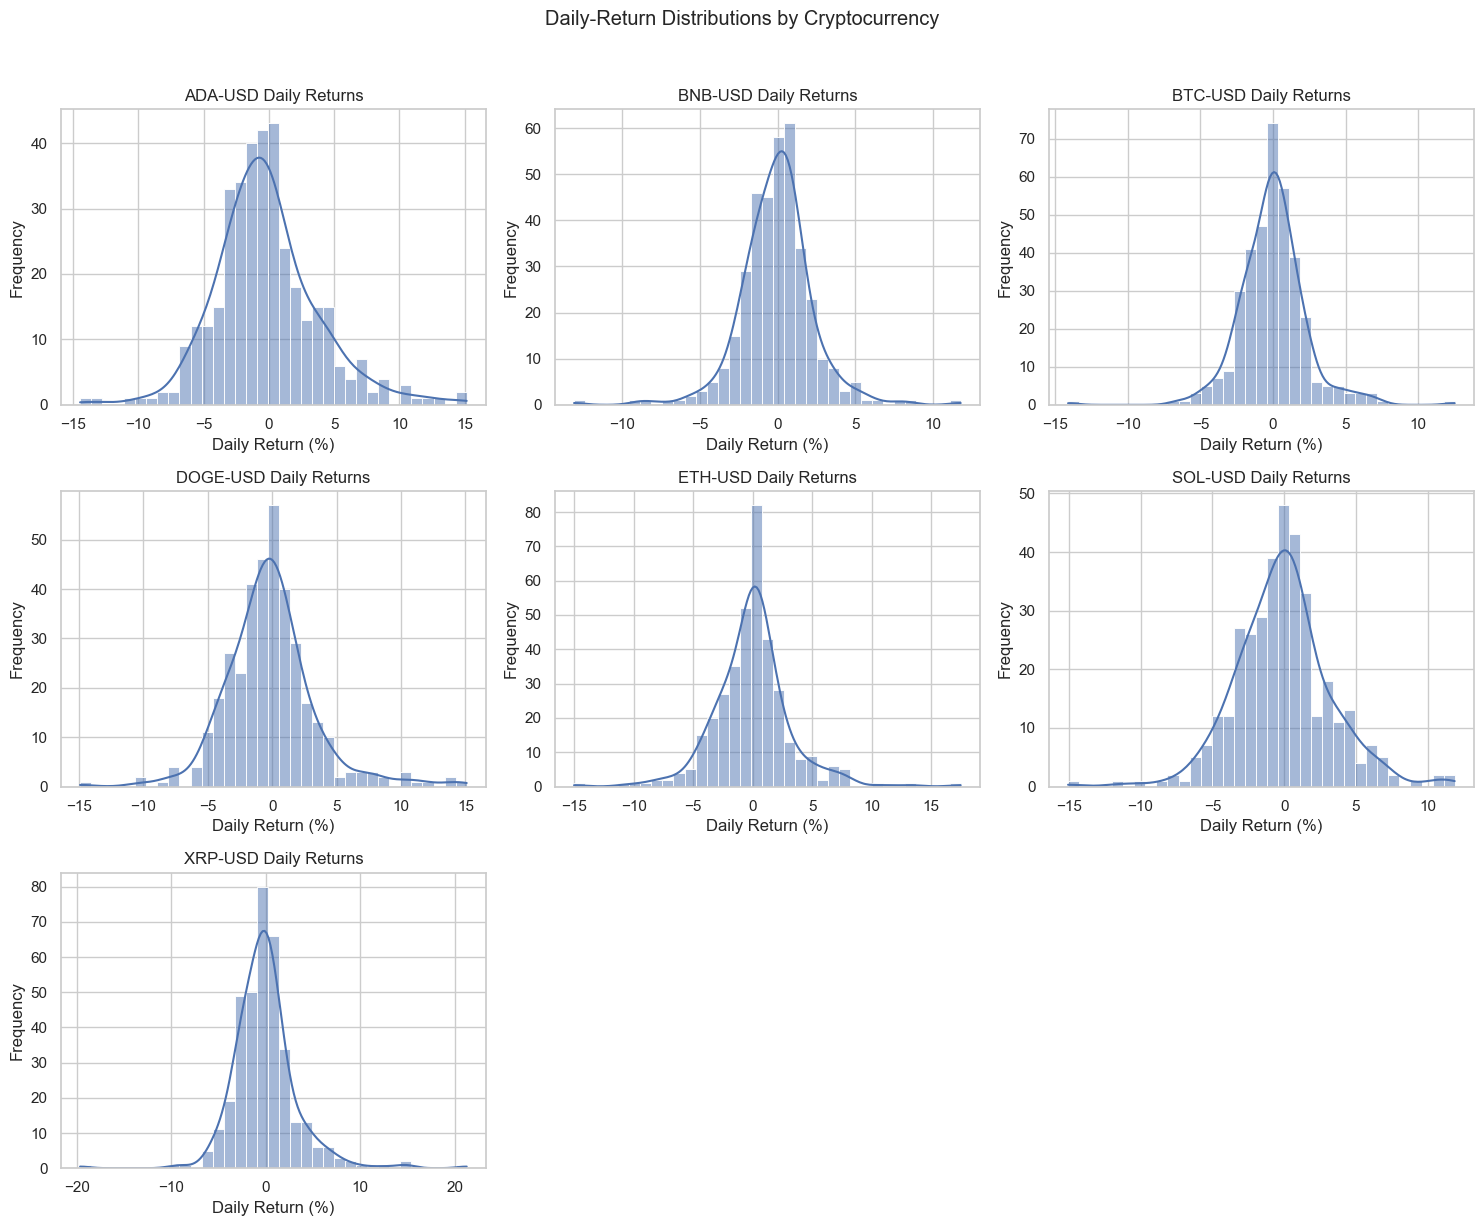

In [166]:

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, symbol in enumerate(available_symbols):
    returns = crypto.loc[
        crypto["Symbol"] == symbol, "Daily_Return_Pct"
    ].dropna()

    sns.histplot(returns, bins=35, kde=True, ax=axes[i])

    axes[i].set_title(f"{symbol} Daily Returns")
    axes[i].set_xlabel("Daily Return (%)")
    axes[i].set_ylabel("Frequency")

for i in range(len(available_symbols), len(axes)):
    axes[i].set_visible(False)

plt.suptitle("Daily-Return Distributions by Cryptocurrency", y=1.02)
plt.tight_layout()
plt.show()



### Interpretation of Univariate Analysis

Each closing-price histogram shows the distribution of daily closing prices for one cryptocurrency during the observation period.

The shape and spread of each distribution help describe the observed price range and potential unusual values. Since cryptocurrencies have different price levels, these charts should be interpreted separately.

Daily-return distributions are more useful for comparing the variability of percentage price changes across cryptocurrencies.


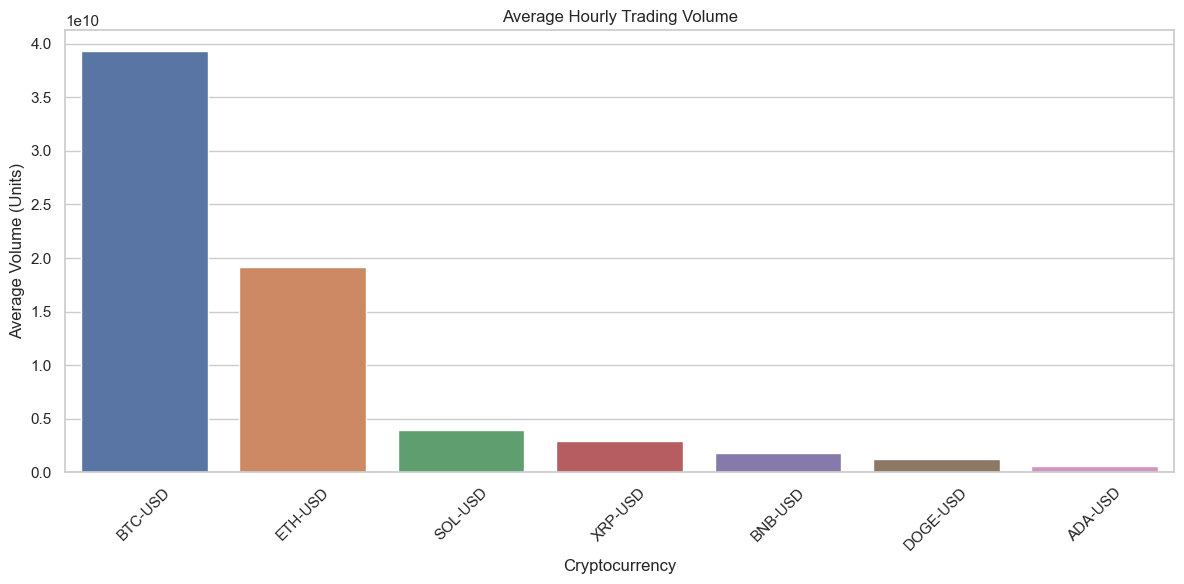

In [167]:
avg_volume = (
    crypto.groupby("Symbol")["Volume"]
    .mean()
    .sort_values(ascending=False)
)

sns.barplot(
    x=avg_volume.index,
    y=avg_volume.values
)

plt.title("Average Hourly Trading Volume")
plt.xlabel("Cryptocurrency")
plt.ylabel("Average Volume (Units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 12. Bivariate and Multivariate Analysis

Bivariate and multivariate analysis examine relationships between two or more variables.

This section compares cryptocurrency performance over time, investigates correlations between daily returns, and explores the relationship between daily returns and trading volume.

The analysis focuses on relative performance and return relationships rather than comparing raw cryptocurrency prices alone.


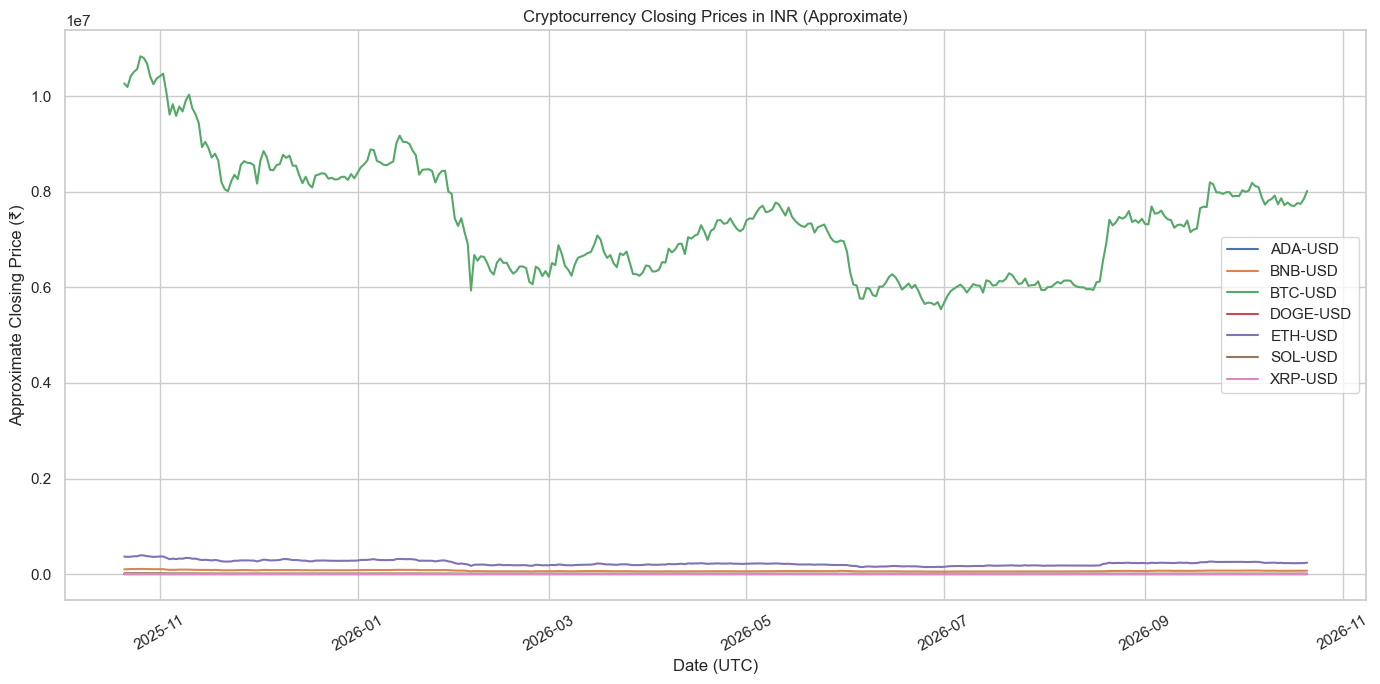

In [168]:

plt.figure(figsize=(14, 7))

for symbol, group in crypto.groupby("Symbol"):
    plt.plot(
        group["Datetime"],
        group["Close_INR_Approx"],
        label=symbol
    )

plt.title("Cryptocurrency Closing Prices in INR (Approximate)")
plt.xlabel("Date (UTC)")
plt.ylabel("Approximate Closing Price (₹)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


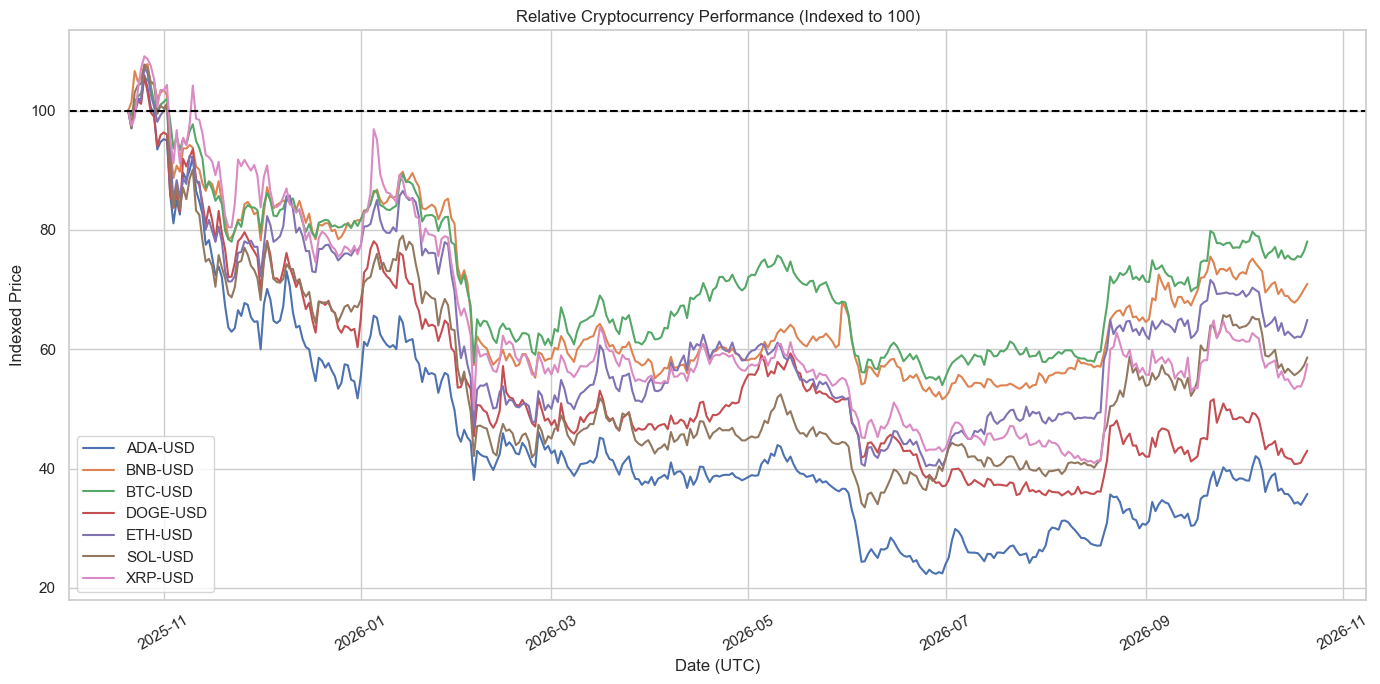

In [169]:

plt.figure(figsize=(14, 7))

for symbol, group in crypto.groupby("Symbol"):
    plt.plot(
        group["Datetime"],
        group["Indexed_Price"],
        label=symbol
    )

plt.axhline(100, linestyle="--", color="black")

plt.title("Relative Cryptocurrency Performance (Indexed to 100)")
plt.xlabel("Date (UTC)")
plt.ylabel("Indexed Price")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


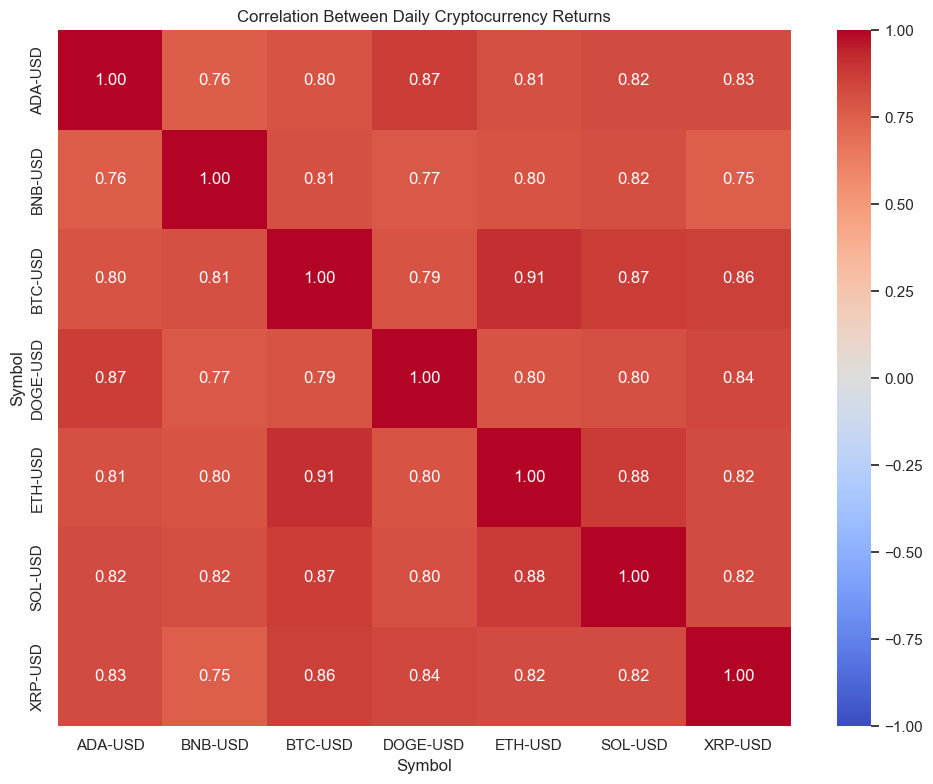

In [170]:

# Align closing prices by date and calculate daily returns
price_table = crypto.pivot(
    index="Datetime",
    columns="Symbol",
    values="Close"
).sort_index()

daily_returns = price_table.pct_change(fill_method=None)

correlation = daily_returns.corr(min_periods=20)

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Correlation Between Daily Cryptocurrency Returns")
plt.tight_layout()
plt.show()


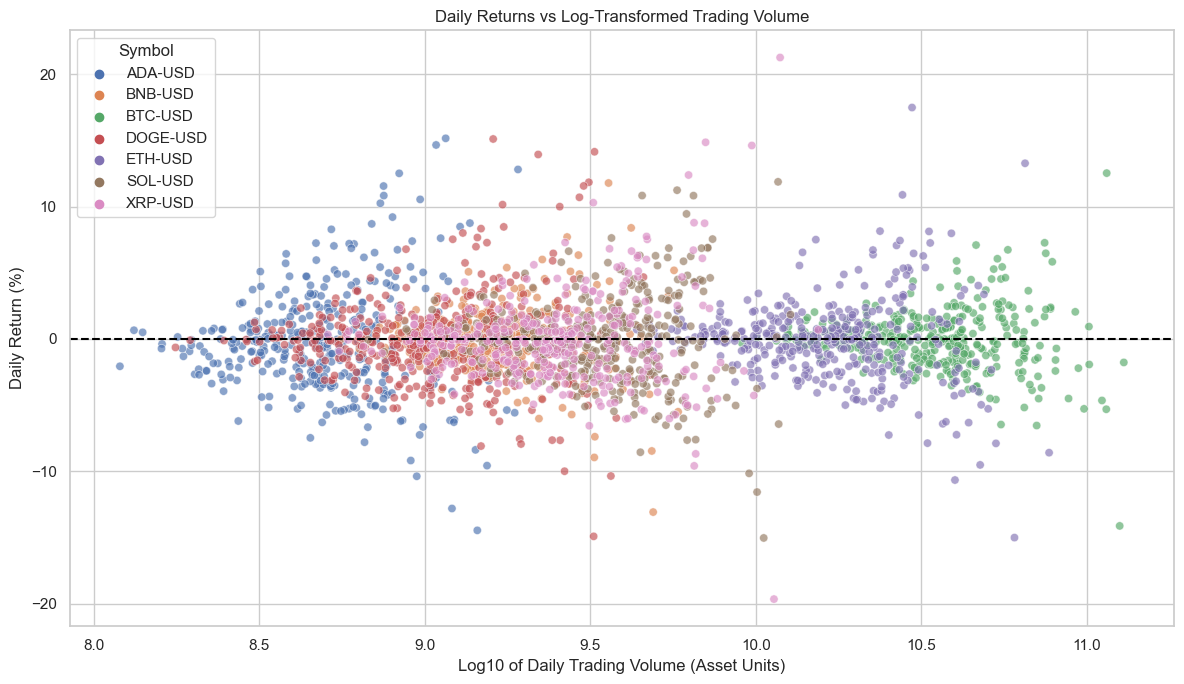

In [171]:

volume_data = crypto.dropna(
    subset=["Daily_Return_Pct", "Volume"]
).copy()

volume_data = volume_data[volume_data["Volume"] > 0].copy()

volume_data["Log10_Volume"] = np.log10(volume_data["Volume"])

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=volume_data,
    x="Log10_Volume",
    y="Daily_Return_Pct",
    hue="Symbol",
    alpha=0.65
)

plt.axhline(0, linestyle="--", color="black")
plt.title("Daily Returns vs Log-Transformed Trading Volume")
plt.xlabel("Log10 of Daily Trading Volume (Asset Units)")
plt.ylabel("Daily Return (%)")
plt.tight_layout()
plt.show()



## 13. Volatility and Maximum Drawdown Analysis

Volatility measures the variability of cryptocurrency returns, while maximum drawdown measures the largest decline from a previous peak during the observation period.

This section compares seven-observation rolling volatility and maximum drawdown for the selected cryptocurrencies.

These metrics provide different perspectives on historical risk. Volatility describes variability in returns, while drawdown measures the depth of a decline from a previous peak.


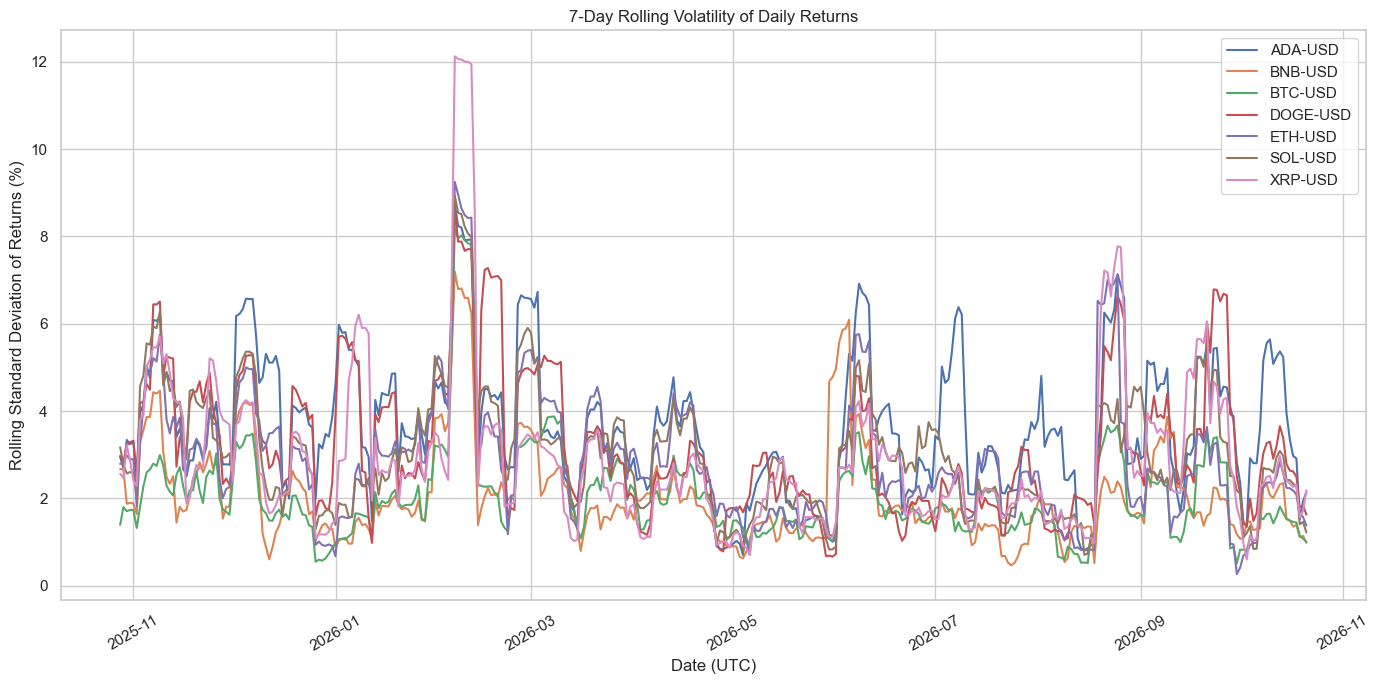

In [172]:

plt.figure(figsize=(14, 7))

for symbol, group in crypto.groupby("Symbol"):
    plt.plot(
        group["Datetime"],
        group["Rolling_Volatility_7d"],
        label=symbol
    )

plt.title("7-Day Rolling Volatility of Daily Returns")
plt.xlabel("Date (UTC)")
plt.ylabel("Rolling Standard Deviation of Returns (%)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


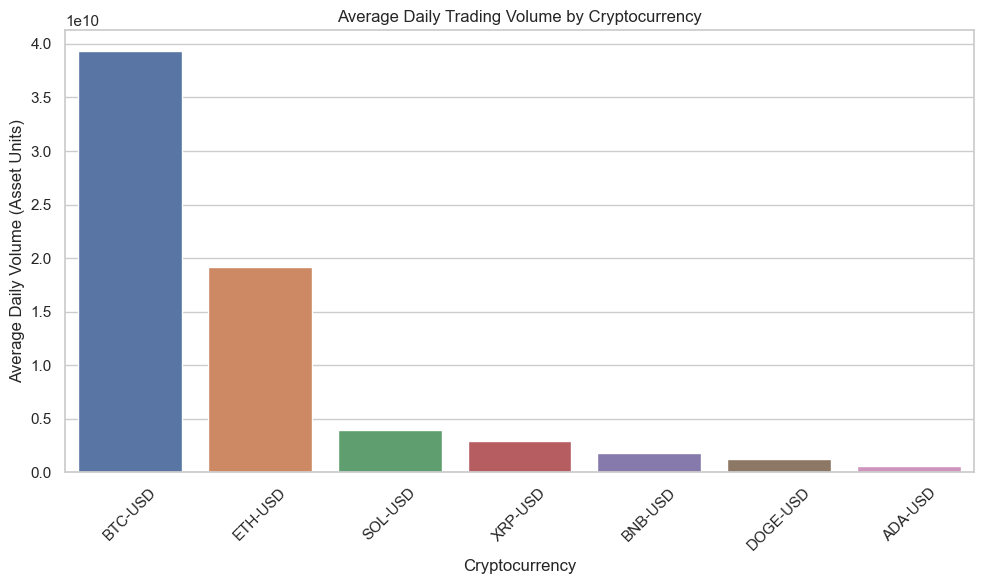

In [173]:

avg_volume = (
    crypto.groupby("Symbol")["Volume"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=avg_volume.index,
    y=avg_volume.values
)

plt.title("Average Daily Trading Volume by Cryptocurrency")
plt.xlabel("Cryptocurrency")
plt.ylabel("Average Daily Volume (Asset Units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### Interpretation of Volatility and Drawdown

The rolling-volatility chart shows how the variability of daily returns changed over time. Higher values indicate more variable returns over the rolling seven-observation window.

The maximum-drawdown chart identifies the deepest observed decline from a previous closing-price peak for each cryptocurrency during the selected period.

Use the actual chart values to compare the assets. These historical measures do not predict future volatility or losses.



## 14. Bitcoin Volatility Regimes and Altcoin Correlation

This analysis investigates whether the correlation between Bitcoin and alternative cryptocurrencies changes during periods of relatively high Bitcoin volatility.

Bitcoin's seven-observation rolling standard deviation of daily returns is used to divide observations into two groups:

- High volatility: Bitcoin rolling volatility is above its 75th percentile.
- Lower volatility: Bitcoin rolling volatility is at or below its 75th percentile.

The correlation between Bitcoin returns and each altcoin's returns is calculated separately for these groups.

This comparison is exploratory. A difference in correlation does not establish that Bitcoin volatility causes changes in altcoin behaviour.


In [174]:

# Align prices by date
price_table = crypto.pivot(
    index="Datetime",
    columns="Symbol",
    values="Close"
).sort_index()

daily_returns = price_table.pct_change(fill_method=None)

# Calculate Bitcoin's rolling volatility
btc_volatility = (
    daily_returns["BTC-USD"]
    .rolling(7, min_periods=7)
    .std()
)

# Define high-volatility threshold
volatility_threshold = btc_volatility.quantile(0.75)

results = []

for symbol in daily_returns.columns:
    if symbol == "BTC-USD":
        continue

    pair = pd.DataFrame({
        "BTC_Return": daily_returns["BTC-USD"],
        "Altcoin_Return": daily_returns[symbol],
        "BTC_Volatility": btc_volatility
    }).dropna()

    high_pair = pair[
        pair["BTC_Volatility"] > volatility_threshold
    ]

    lower_pair = pair[
        pair["BTC_Volatility"] <= volatility_threshold
    ]

    high_corr = (
        high_pair["BTC_Return"].corr(high_pair["Altcoin_Return"])
        if len(high_pair) >= 10 else np.nan
    )

    lower_corr = (
        lower_pair["BTC_Return"].corr(lower_pair["Altcoin_Return"])
        if len(lower_pair) >= 10 else np.nan
    )

    results.append({
        "Cryptocurrency": symbol,
        "High_Volatility_Correlation": high_corr,
        "Lower_Volatility_Correlation": lower_corr,
        "High_Volatility_Observations": len(high_pair),
        "Lower_Volatility_Observations": len(lower_pair)
    })

regime_results = pd.DataFrame(results).set_index("Cryptocurrency")

print("Bitcoin volatility threshold:", volatility_threshold)

display(regime_results.round(3))


Bitcoin volatility threshold: 0.025018148735364752


,High_Volatility_Correlation,Lower_Volatility_Correlation,High_Volatility_Observations,Lower_Volatility_Observations
Cryptocurrency,,,,
ADA-USD,0.854,0.745,90,269
BNB-USD,0.909,0.716,90,269
DOGE-USD,0.861,0.724,90,269
ETH-USD,0.922,0.887,90,269
SOL-USD,0.901,0.837,90,269
XRP-USD,0.894,0.823,90,269


In [175]:

regime_results["Correlation_Difference"] = (
    regime_results["High_Volatility_Correlation"]
    - regime_results["Lower_Volatility_Correlation"]
)

print("Correlation comparison by volatility regime:")
display(
    regime_results[
        [
            "High_Volatility_Correlation",
            "Lower_Volatility_Correlation",
            "Correlation_Difference",
            "High_Volatility_Observations",
            "Lower_Volatility_Observations"
        ]
    ].round(3)
)


Correlation comparison by volatility regime:


,High_Volatility_Correlation,Lower_Volatility_Correlation,Correlation_Difference,High_Volatility_Observations,Lower_Volatility_Observations
Cryptocurrency,,,,,
ADA-USD,0.854,0.745,0.109,90,269
BNB-USD,0.909,0.716,0.193,90,269
DOGE-USD,0.861,0.724,0.137,90,269
ETH-USD,0.922,0.887,0.035,90,269
SOL-USD,0.901,0.837,0.064,90,269
XRP-USD,0.894,0.823,0.071,90,269



### Interpretation of Bitcoin Volatility Regimes

Compare the correlation values during high- and lower-volatility periods for each cryptocurrency. Higher correlation during high-volatility periods would indicate that the asset's daily returns moved more closely with Bitcoin in that subset of observations.

Check the observation counts before interpreting the results. The findings apply only to the selected historical period and do not establish causation.



## 15. Day-of-Week Return Analysis

This section examines whether average daily cryptocurrency returns differ across weekdays.

Daily returns are grouped by weekday and cryptocurrency. A heatmap is used to compare the average returns observed on different days.

The results describe the selected historical sample and should not be interpreted as evidence of a reliable trading strategy.


Average daily returns by weekday (%):


Weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Symbol,,,,,,,
ADA-USD,0.112,-0.434,-0.422,-0.968,0.730,-0.051,-0.387
BNB-USD,-0.038,-0.305,-0.076,-0.630,0.275,0.322,-0.011
BTC-USD,0.341,-0.297,-0.071,-0.533,0.190,-0.030,0.113
DOGE-USD,-0.119,-0.145,-0.457,-1.010,0.804,0.058,-0.317
ETH-USD,0.547,-0.303,0.180,-1.226,0.214,0.028,0.086
SOL-USD,0.377,-0.441,-0.188,-0.834,0.525,-0.086,0.015
XRP-USD,0.518,-0.542,-0.570,-0.954,0.696,0.204,-0.004


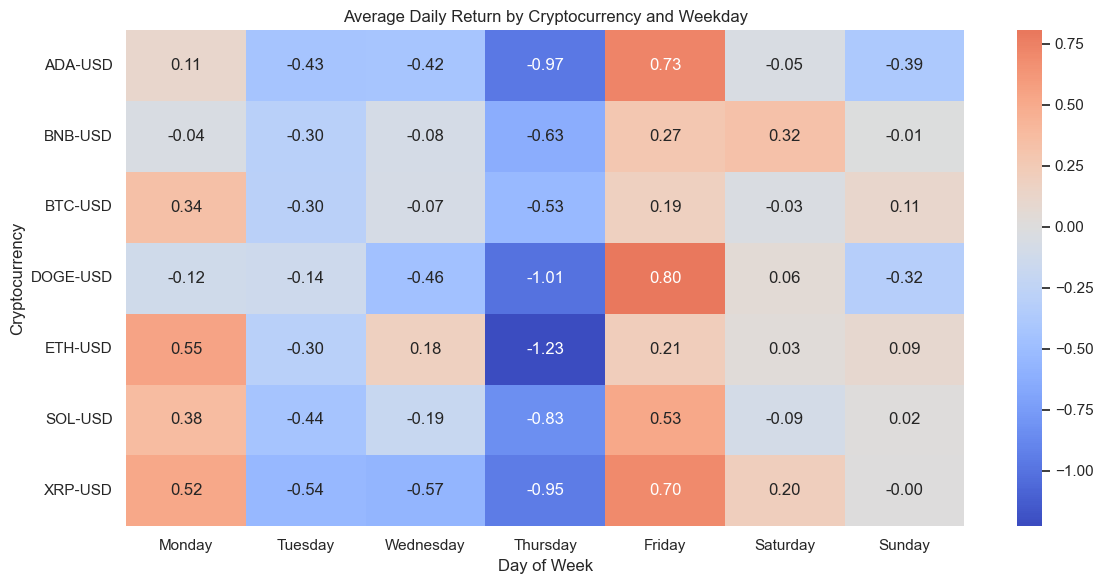

In [176]:

weekday_data = crypto.dropna(
    subset=["Daily_Return_Pct"]
).copy()

weekday_data["Weekday"] = (
    weekday_data["Datetime"].dt.day_name()
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_summary = (
    weekday_data.groupby(["Symbol", "Weekday"])["Daily_Return_Pct"]
    .mean()
    .unstack("Weekday")
    .reindex(columns=weekday_order)
)

print("Average daily returns by weekday (%):")
display(weekday_summary.round(3))

plt.figure(figsize=(12, 6))

sns.heatmap(
    weekday_summary,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Average Daily Return by Cryptocurrency and Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Cryptocurrency")
plt.tight_layout()
plt.show()



## 16. Statistical Summary and Performance Comparison

This section summarises cryptocurrency performance and risk over the observation period.

The summary includes first and latest closing prices, average price, highest and lowest prices, average daily trading volume, daily-return volatility, period return, maximum drawdown, and latest approximate INR price.

Period return is calculated using the first and latest observed closing prices for each cryptocurrency. All results describe the historical dataset and are not predictions of future performance.


In [177]:

summary = (
    crypto.groupby("Symbol")
    .agg(
        First_Price=("Close", "first"),
        Latest_Price=("Close", "last"),
        Average_Price=("Close", "mean"),
        Highest_Price=("High", "max"),
        Lowest_Price=("Low", "min"),
        Average_Daily_Volume=("Volume", "mean"),
        Daily_Return_Volatility=("Daily_Return_Pct", "std"),
        Maximum_Drawdown_Pct=("Drawdown_Pct", "min")
    )
)

# Calculate period return
summary["Period_Return_Pct"] = (
    (summary["Latest_Price"] - summary["First_Price"])
    / summary["First_Price"]
) * 100

# Include approximate INR values if conversion succeeded
if "Close_INR_Approx" in crypto.columns:
    latest_inr = crypto.groupby("Symbol")["Close_INR_Approx"].last()
    summary["Latest_Approx_INR"] = latest_inr

# Sort by period return
summary = summary.sort_values(
    "Period_Return_Pct",
    ascending=False
).round(3)

print("Cryptocurrency Performance and Risk Summary")
display(summary)

print("\nHighest observed period return:")
print(summary["Period_Return_Pct"].idxmax())

print("\nLowest observed period return:")
print(summary["Period_Return_Pct"].idxmin())

print("\nHighest daily-return volatility:")
print(summary["Daily_Return_Volatility"].idxmax())

print("\nLargest observed drawdown:")
print(summary["Maximum_Drawdown_Pct"].idxmin())


Cryptocurrency Performance and Risk Summary


,First_Price,Latest_Price,Average_Price,Highest_Price,Lowest_Price,Average_Daily_Volume,Daily_Return_Volatility,Maximum_Drawdown_Pct,Period_Return_Pct,Latest_Approx_INR
Symbol,,,,,,,,,,
BTC-USD,108476.891,84713.148,78046.900,116273.312,57747.766,3.930208e+10,2.312,-48.845,-21.907,8018946.631
BNB-USD,1057.440,750.600,722.455,1180.015,538.599,1.825316e+09,2.346,-52.122,-29.017,71051.794
ETH-USD,3876.764,2517.060,2426.809,4250.670,1506.506,1.914626e+10,3.207,-62.366,-35.073,238264.905
SOL-USD,185.666,108.870,102.895,205.020,60.415,3.895517e+09,3.341,-68.910,-41.363,10305.634
XRP-USD,2.424,1.395,1.536,2.693,0.988,2.871653e+09,3.404,-62.498,-42.465,132.032
DOGE-USD,0.194,0.084,0.106,0.209,0.068,1.206837e+09,3.504,-66.457,-56.999,7.913
ADA-USD,0.643,0.230,0.287,0.692,0.139,5.609003e+08,3.971,-78.940,-64.236,21.765



Highest observed period return:
BTC-USD

Lowest observed period return:
ADA-USD

Highest daily-return volatility:
ADA-USD

Largest observed drawdown:
ADA-USD



## 17. Key Findings

The following findings will be completed after reviewing the actual outputs of the analysis.

1. **Period performance:** Identify the cryptocurrencies with the highest and lowest observed period returns.
2. **Return volatility:** Identify the cryptocurrency with the highest standard deviation of daily returns.
3. **Maximum drawdown:** Identify the cryptocurrency with the deepest observed decline from a previous peak.
4. **Relative performance:** Compare indexed-price trends across the selected cryptocurrencies.
5. **Return correlations:** Identify the strongest positive and negative relationships between daily returns.
6. **Bitcoin volatility regimes:** Compare altcoin–Bitcoin correlations during high- and lower-volatility periods.
7. **Trading volume:** Examine the relationship between daily returns and trading volume.
8. **Weekday patterns:** Compare average daily returns across weekdays.

All findings must be supported by the calculated statistics and charts. Historical results do not guarantee future performance.



## 18. Conclusion

This project applies Exploratory Data Analysis (EDA) to approximately one year of daily cryptocurrency market data collected from Yahoo Finance.

The analysis includes data collection, data cleaning, descriptive statistics, daily-return calculations, relative performance comparisons, rolling volatility, maximum drawdown, return correlation, Bitcoin volatility-regime analysis, and day-of-week comparisons.

These analyses provide a structured understanding of historical cryptocurrency market behaviour and differences in observed performance and risk.

The project has limitations. Data availability may vary across cryptocurrencies, results depend on the selected observation period, and short rolling windows can be sensitive to large daily movements. INR prices are approximate because a single reference exchange rate is applied to all historical observations.

This project is descriptive and does not predict future cryptocurrency prices or provide financial advice. Future improvements could include date-specific historical exchange rates, a longer observation period, and an interactive dashboard.



## 19. Exporting the Dataset and Results

After completing the analysis, the cleaned dataset and summary statistics are exported to CSV files. These files can be reused for further analysis, shared as project outputs, or included in the GitHub repository, subject to the data source's terms.

In [178]:

# 1. Export the cleaned dataset with engineered features
crypto.to_csv(
    "crypto_market_data_cleaned.csv",
    index=False
)

# 2. Export the performance and risk summary
summary.to_csv(
    "crypto_eda_summary.csv",
    index=True
)

# 3. Export the volatility-regime analysis
regime_results.to_csv(
    "bitcoin_volatility_regime_analysis.csv",
    index=True
)

# 4. Export the daily-return correlation matrix
correlation.to_csv(
    "crypto_return_correlation.csv",
    index=True
)

# 5. Export weekday analysis
weekday_summary.to_csv(
    "crypto_weekday_return_analysis.csv",
    index=True
)

print("All exports completed successfully.")

print("\nFiles created:")
print("1. crypto_market_data_cleaned.csv")
print("2. crypto_eda_summary.csv")
print("3. bitcoin_volatility_regime_analysis.csv")
print("4. crypto_return_correlation.csv")
print("5. crypto_weekday_return_analysis.csv")

print("\nFinal dataset information:")
print("Rows:", len(crypto))
print("Cryptocurrencies:", crypto["Symbol"].nunique())
print("First date:", crypto["Datetime"].min())
print("Last date:", crypto["Datetime"].max())


All exports completed successfully.

Files created:
1. crypto_market_data_cleaned.csv
2. crypto_eda_summary.csv
3. bitcoin_volatility_regime_analysis.csv
4. crypto_return_correlation.csv
5. crypto_weekday_return_analysis.csv

Final dataset information:
Rows: 2562
Cryptocurrencies: 7
First date: 2025-10-21 00:00:00+00:00
Last date: 2026-10-21 00:00:00+00:00



## 20. Reproducibility and Limitations

### Reproducibility

- Cryptocurrency data is collected from Yahoo Finance through `yfinance`.
- The analysis uses seven cryptocurrencies and approximately one year of daily observations.
- The notebook contains the steps for data collection, cleaning, feature engineering, analysis, and export.
- Re-running the notebook may produce different results as new market data becomes available.

### Limitations

- Data availability and the behaviour of external libraries may change.
- Results depend on the selected assets and observation period.
- Rolling volatility is sensitive to large daily movements.
- Correlation does not establish causation.
- INR prices are approximate because one reference exchange rate is applied to all historical dates.
- Historical performance does not guarantee future returns.
